In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 11 · Synthesis: pipeline, hypothesis verdicts and conclusions

This notebook assembles the evidence from notebooks 06-10 into (i) the end-to-end pipeline diagram, (ii) the crop-phenology timeline of the
16-week window, (iii) a machine-computed verdict for every research question / hypothesis of the proposal, and (iv) the master results table used in the paper
(`docs/research_paper.md`). **Verdicts are generated from the saved result tables by explicit decision rules** - they are not typed in.

In [2]:
import matplotlib.patches as mp
from src.experiment import *
from src.weather_features import STAGES
M = pd.read_csv(TAB/"p2_main_summary_test.csv"); BT = pd.read_csv(TAB/"p2_main_paired_bootstrap.csv")
RB = pd.read_csv(TAB/"p2_rolling_origin_bootstrap.csv"); SQ = pd.read_csv(TAB/"p3_sequence_summary_test.csv"); PT = pd.read_csv(TAB/"p3_sequence_paired_bootstrap.csv")
FE = pd.read_csv(TAB/"p2_panel_fe_lag_coefficients.csv"); R2 = pd.read_csv(TAB/"p2_panel_fe_r2_decomposition.csv"); SH = pd.read_csv(TAB/"p2_control_shuffle_summary.csv")
AN = pd.read_csv(TAB/"p2_control_anchor_shift_summary.csv"); REF = pd.read_csv(TAB/"p2_reference_forecasts_test.csv", index_col=0)

## 1 · End-to-end pipeline

saved -> results/figures/p2_11_pipeline.png


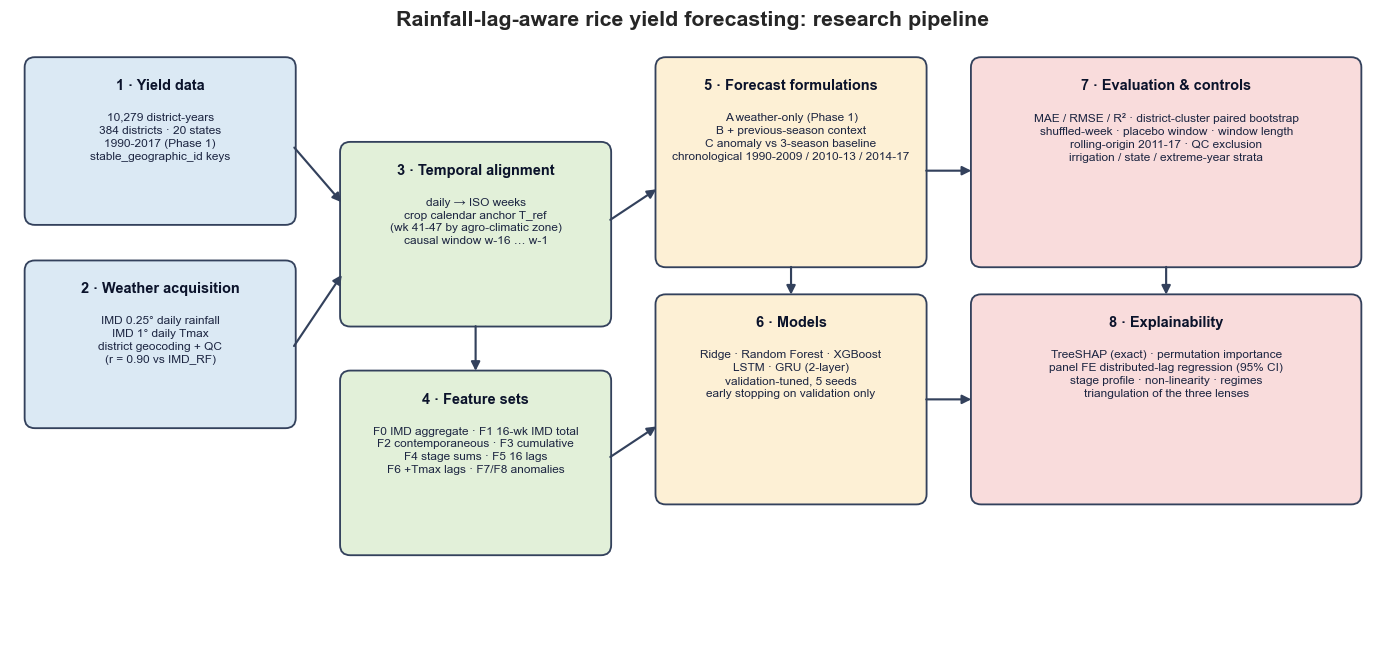

In [3]:
fig, ax = plt.subplots(figsize=(16, 7.2)); ax.set_xlim(0, 16); ax.set_ylim(0, 7.2); ax.axis("off")
def box(x, y, w, h, title, body, color):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=color, ec="#33415c", lw=1.2))
    ax.text(x + w / 2, y + h - 0.22, title, ha="center", va="top", fontweight="bold", fontsize=9.5, color="#0b132b")
    ax.text(x + w / 2, y + h - 0.62, body, ha="center", va="top", fontsize=7.8, color="#1c2541", linespacing=1.35)
def arrow(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#33415c", lw=1.4))
C1, C2, C3, C4 = "#dbe9f4", "#e2f0d9", "#fdf0d5", "#f9dcdc"
box(0.2, 5.0, 3.1, 1.9, "1 · Yield data", "10,279 district-years\n384 districts · 20 states\n1990-2017 (Phase 1)\nstable_geographic_id keys", C1)
box(0.2, 2.6, 3.1, 1.9, "2 · Weather acquisition", "IMD 0.25° daily rainfall\nIMD 1° daily Tmax\ndistrict geocoding + QC\n(r = 0.90 vs IMD_RF)", C1)
box(3.9, 3.8, 3.1, 2.1, "3 · Temporal alignment", "daily → ISO weeks\ncrop calendar anchor T_ref\n(wk 41-47 by agro-climatic zone)\ncausal window w-16 … w-1", C2)
box(3.9, 1.1, 3.1, 2.1, "4 · Feature sets", "F0 IMD aggregate · F1 16-wk IMD total\nF2 contemporaneous · F3 cumulative\nF4 stage sums · F5 16 lags\nF6 +Tmax lags · F7/F8 anomalies", C2)
box(7.6, 4.5, 3.1, 2.4, "5 · Forecast formulations", "A weather-only (Phase 1)\nB + previous-season context\nC anomaly vs 3-season baseline\nchronological 1990-2009 / 2010-13 / 2014-17", C3)
box(7.6, 1.7, 3.1, 2.4, "6 · Models", "Ridge · Random Forest · XGBoost\nLSTM · GRU (2-layer)\nvalidation-tuned, 5 seeds\nearly stopping on validation only", C3)
box(11.3, 4.5, 4.5, 2.4, "7 · Evaluation & controls", "MAE / RMSE / R² · district-cluster paired bootstrap\nshuffled-week · placebo window · window length\nrolling-origin 2011-17 · QC exclusion\nirrigation / state / extreme-year strata", C4)
box(11.3, 1.7, 4.5, 2.4, "8 · Explainability", "TreeSHAP (exact) · permutation importance\npanel FE distributed-lag regression (95% CI)\nstage profile · non-linearity · regimes\ntriangulation of the three lenses", C4)
for a in [(3.3, 5.9, 3.9, 5.2), (3.3, 3.5, 3.9, 4.4), (5.45, 3.8, 5.45, 3.2), (7.0, 2.2, 7.6, 2.6), (7.0, 5.0, 7.6, 5.4), (10.7, 5.6, 11.3, 5.6), (10.7, 2.9, 11.3, 2.9), (9.15, 4.5, 9.15, 4.1), (13.55, 4.5, 13.55, 4.1)]: arrow(*a)
ax.set_title("Rainfall-lag-aware rice yield forecasting: research pipeline", fontsize=14, fontweight="bold", y=1.0)
savefig("p2_11_pipeline"); plt.show()

## 2 · Phenology timeline of the 16-week window

saved -> results/figures/p2_11_phenology_timeline.png


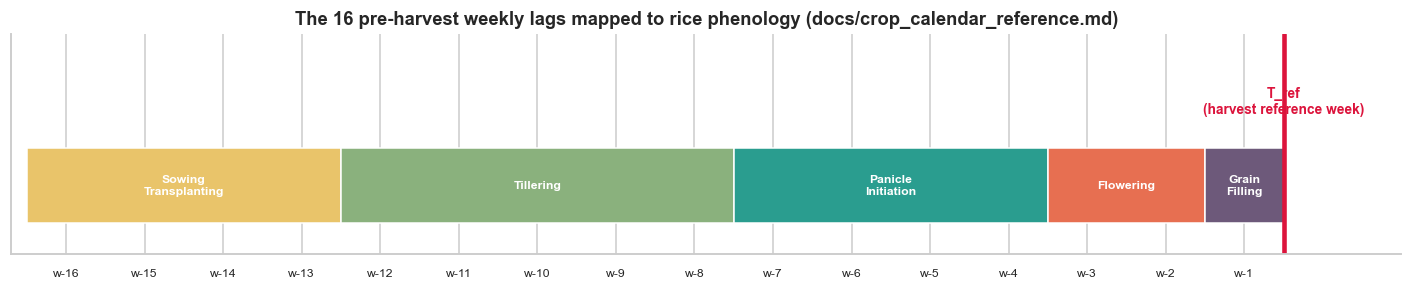

In [4]:
fig, ax = plt.subplots(figsize=(13, 2.8)); cols = ["#e9c46a", "#8ab17d", "#2a9d8f", "#e76f51", "#6d597a"]
for (s, ks), c in zip(STAGES.items(), cols):
    ax.barh(0, max(ks) - min(ks) + 1, left=16 - max(ks), color=c, edgecolor="white", height=.55)
    ax.text(16 - max(ks) + (max(ks) - min(ks) + 1) / 2, 0, s.split("_", 1)[1].replace("_", "\n"), ha="center", va="center", fontsize=8, color="white", fontweight="bold")
ax.axvline(16, color="crimson", lw=3); ax.text(16, .5, "T_ref\n(harvest reference week)", color="crimson", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_xlim(-.2, 17.5); ax.set_ylim(-.5, 1.1); ax.set_yticks([]); ax.set_xticks(np.arange(.5, 16)); ax.set_xticklabels([f"w-{k}" for k in range(16, 0, -1)], fontsize=8)
ax.set_title("The 16 pre-harvest weekly lags mapped to rice phenology (docs/crop_calendar_reference.md)"); plt.tight_layout(); savefig("p2_11_phenology_timeline"); plt.show()

## 3 · Machine-computed verdicts

Decision rules (stated before looking at the verdict column):

* **H1 - lag-aware representation lowers forecast error.** Supported only if the lag representation's paired-bootstrap Δ MAE vs the **same-source aggregate (F1)** is negative *with the 95 % CI entirely below 0* in the majority of (tier × model) cells for RF and XGBoost; refuted if it is positive/CI above 0 in the majority; otherwise inconclusive.
* **H1b - temporal *order* is exploited.** Supported only if shuffling the weeks *raises* MAE for both tree models; also checked on LSTM/GRU.
* **H2 - timing carries a structured signal.** Supported if the panel regression rejects equality of the 16 coefficients at 5 %.
* **H3 - the right calendar window matters.** Supported if the true window (shift 0) is at least as good as every placebo window shifted ≥ 6 weeks for both tree models.

In [5]:
cell = BT[(BT.A == "F5_Lag16") & (BT.B == "F1_Aggregate_IMDgrid") & BT.model.isin(["RF", "XGB"])]
better, worse = ((cell.ci_hi < 0)).sum(), ((cell.ci_lo > 0)).sum()
h1 = "SUPPORTED" if better > len(cell) / 2 else "NOT SUPPORTED (lags are worse/no better)" if worse >= better and (cell.delta_mae > 0).sum() > len(cell) / 2 else "INCONCLUSIVE"
sh_delta = SH.pivot_table(index=["base", "model"], columns="condition", values="mean"); sh_delta["delta"] = sh_delta["shuffled weeks"] - sh_delta["true order"]
h1b_trees = "SUPPORTED" if (sh_delta.delta > 0).all() else "NOT SUPPORTED (shuffling does not hurt)"
def _seq(tier):
    x = PT[(PT.tier == tier) & (PT.true_vs == "shuffled_weeks")]
    return ", ".join(f"{r.model} {r.delta_mae:+.1f} [{r.ci_lo:+.1f},{r.ci_hi:+.1f}]" for r in x.itertuples()), bool((x.ci_hi < 0).all())
txt_c, ok_c = _seq("C_anomaly"); txt_a, ok_a = _seq("A_weather_only")
h1b_seq = f"recurrent nets Δ MAE(true−shuffled): tier C {txt_c} -> {'SUPPORTED' if ok_c else 'NOT SUPPORTED'}; tier A {txt_a} -> {'SUPPORTED' if ok_a else 'NOT SUPPORTED / partly'}"

In [6]:
from src.panel import lag_coefficients
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz"); from src.experiment import add_rain_anomalies; D = add_rain_anomalies(D, 2009)
res = lag_coefficients(D); h2_p = res["wald_equal"][1]; h2 = "SUPPORTED" if h2_p < .05 else "NOT SUPPORTED"
g = AN[AN.base_feature_set == "F5_Lag16"].pivot(index="anchor_shift_weeks", columns="model", values="mean")
h3 = "SUPPORTED" if all((g.loc[0, m] <= g.loc[g.index >= 6, m]).all() for m in ["RF", "XGB"]) else "NOT SUPPORTED"
best_w = FE.loc[FE.p_value.nsmallest(5).index].sort_values("weeks_before_harvest")
inc = R2.set_index("model").incremental_within_R2_pct
V = pd.DataFrame([
 ["H1  lag representation lowers forecast error (vs same-source aggregate)", f"RF/XGB, tiers A-C: Δ MAE(F5−F1) = {', '.join(f'{v:+.1f}' for v in cell.delta_mae)} kg/ha; CI strictly below 0 in {better}/{len(cell)} cells", h1],
 ["H1b temporal order is exploited (shuffled-week control)", f"MAE(shuffled − true): " + ", ".join(f"{i[0][:2]}/{i[1]} {v:+.1f}" for i, v in sh_delta.delta.items()), f"trees: {h1b_trees}; {h1b_seq}"],
 ["H2  rainfall timing carries structured information (explanatory)", f"panel FE, H0 equal coefficients: p = {h2_p:.1e}; weekly lags add {inc['+ 16 weekly anomalies'] - inc['+ seasonal total anomaly']:.2f} pp of FE-residual variance beyond the total ({inc['+ seasonal total anomaly']:.2f} % → {inc['+ 16 weekly anomalies']:.2f} %)", h2],
 ["H3  the true calendar window matters (placebo windows)", "MAE by anchor shift (F5): " + "; ".join(f"{m}: {g.loc[0, m]:.1f} → {g.loc[16, m]:.1f}" for m in ["RF", "XGB"]) + " (shift 0 → 16)", h3],
], columns=["Hypothesis / question", "Evidence (computed)", "Verdict"])
V.to_csv(TAB/"p2_hypothesis_verdicts.csv", index=False)
pd.set_option("display.max_colwidth", 200); V

,Hypothesis / question,Evidence (computed),Verdict
0,H1 lag representation lowers forecast error (vs same-source aggregate),"RF/XGB, tiers A-C: Δ MAE(F5−F1) = +4.2, +8.1, +12.7, -6.8, +3.3, +3.3 kg/ha; CI strictly below 0 in 1/6 cells",NOT SUPPORTED (lags are worse/no better)
1,H1b temporal order is exploited (shuffled-week control),"MAE(shuffled − true): F5/RF -0.8, F5/XGB -5.4, F7/RF -2.4, F7/XGB -4.8","trees: NOT SUPPORTED (shuffling does not hurt); recurrent nets Δ MAE(true−shuffled): tier C LSTM +2.3 [+0.8,+3.6], GRU +1.2 [-0.4,+2.7] -> NOT SUPPORTED; tier A LSTM -4.0 [-7.9,+0.0], GRU -17.8 [-..."
2,H2 rainfall timing carries structured information (explanatory),"panel FE, H0 equal coefficients: p = 3.1e-08; weekly lags add 0.52 pp of FE-residual variance beyond the total (1.01 % → 1.53 %)",SUPPORTED
3,H3 the true calendar window matters (placebo windows),MAE by anchor shift (F5): RF: 332.8 → 342.4; XGB: 337.8 → 359.5 (shift 0 → 16),SUPPORTED


## 4 · Where in the season does rainfall matter? (RQ2)

In [7]:
st = pd.read_csv(TAB/"p2_panel_fe_stage_coefficients.csv"); print("Panel FE, stage-level (% yield per +100 mm rain anomaly):"); print(st.round(3).to_string(index=False))
top = FE.reindex(FE.coef_pct_per_100mm.abs().sort_values(ascending=False).index).head(6)[["weeks_before_harvest", "coef_pct_per_100mm", "ci_lo", "ci_hi", "p_value"]]
print("\nSix largest weekly effects:"); print(top.round(3).to_string(index=False))

Panel FE, stage-level (% yield per +100 mm rain anomaly):
                  stage  coef_pct_per_100mm  ci_lo  ci_hi  p_value
S1_Sowing_Transplanting               1.125  0.502  1.747    0.000
           S2_Tillering               1.343  0.833  1.854    0.000
  S3_Panicle_Initiation               1.879  1.143  2.616    0.000
           S4_Flowering               1.394  0.082  2.707    0.037
       S5_Grain_Filling               5.225  3.145  7.305    0.000

Six largest weekly effects:
 weeks_before_harvest  coef_pct_per_100mm  ci_lo  ci_hi  p_value
                   -1               5.032  2.923  7.141    0.000
                   -2               3.274  1.341  5.206    0.001
                   -7               3.075  1.663  4.487    0.000
                  -13               2.572  1.485  3.658    0.000
                   -5               2.154  1.009  3.299    0.000
                   -8               2.075  0.974  3.177    0.000


## 5 · Master results table (test years 2014-2017)

In [8]:
rows = []
for tier in ["A_weather_only", "B_level_plus_context", "C_anomaly"]:
    s = M[M.tier == tier]
    for fs in FEATURE_SETS:
        for mod in ["RF", "XGB", "Ridge"]:
            r = s[(s.feature_set == fs) & (s.model == mod)].iloc[0]; rows.append(dict(tier=tier, feature_set=fs, model=mod, MAE=r.MAE, MAE_sd=r.MAE_sd, RMSE=r.RMSE, R2=r.R2))
Mast = pd.DataFrame(rows)
for r in SQ.itertuples(): rows.append(dict(tier=r.tier, feature_set=f"seq:{r.condition}", model=r.model, MAE=r.MAE, MAE_sd=r.MAE_sd, RMSE=r.RMSE, R2=r.R2))
Mast = pd.DataFrame(rows); Mast.to_csv(TAB/"p2_master_results_test.csv", index=False)
bt = Mast.sort_values("MAE").groupby("tier").head(3); bt

,tier,feature_set,model,MAE,MAE_sd,RMSE,R2
90,C_anomaly,seq:shuffled_weeks,LSTM,327.284,2.690,475.535,0.765
89,C_anomaly,seq:shuffled_weeks,GRU,328.255,1.123,476.690,0.764
78,C_anomaly,F8_Total_Anomaly,RF,329.023,0.277,477.765,0.763
40,B_level_plus_context,F4_Stage,XGB,347.626,0.712,494.263,0.747
43,B_level_plus_context,F5_Lag16,XGB,347.957,1.494,492.766,0.748
49,B_level_plus_context,F7_Lag16_Anomaly,XGB,348.884,1.161,490.299,0.751
85,A_weather_only,seq:true_order,GRU,679.573,7.734,863.235,0.227
86,A_weather_only,seq:true_order,LSTM,687.876,6.479,872.018,0.211
84,A_weather_only,seq:shuffled_weeks,LSTM,691.895,5.383,875.115,0.206


## 6 · Final summary figure

saved -> results/figures/p2_11_summary_figure.png


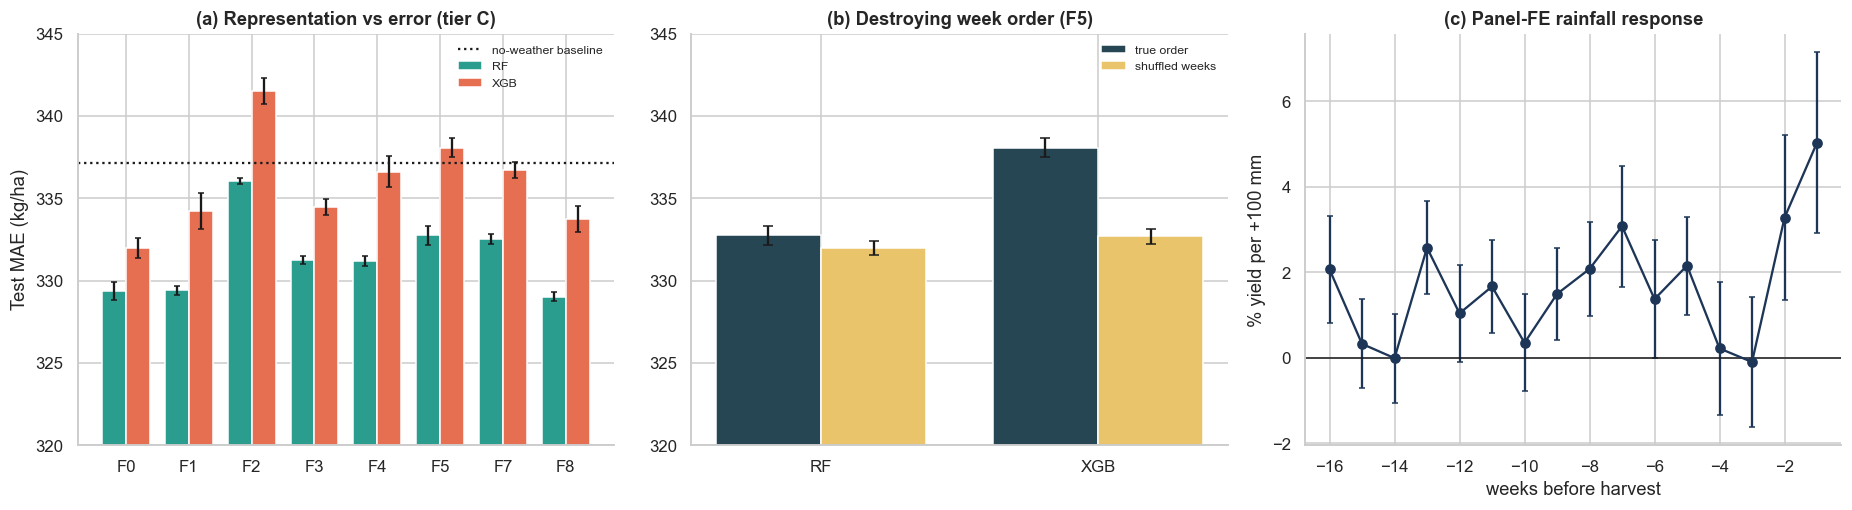

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
# (a) representation comparison, tier C RF/XGB
s = M[(M.tier == "C_anomaly") & M.model.isin(["RF", "XGB"])]; order = [f for f in FEATURE_SETS if f != "F6_Lag16_PlusTmaxLags"]
for k, (mod, c) in enumerate([("RF", "#2a9d8f"), ("XGB", "#e76f51")]):
    q = s[s.model == mod].set_index("feature_set").loc[order]; axs[0].bar(np.arange(len(order)) + (k - .5) * .38, q.MAE, .38, yerr=q.MAE_sd, color=c, label=mod, capsize=2)
axs[0].axhline(REF.loc["District baseline = mean of last 3 seasons", "MAE"], color="k", ls=":", label="no-weather baseline"); axs[0].set_ylim(320, 345)
axs[0].set_xticks(range(len(order))); axs[0].set_xticklabels([o.split("_")[0] for o in order]); axs[0].set_ylabel("Test MAE (kg/ha)"); axs[0].set_title("(a) Representation vs error (tier C)"); axs[0].legend(frameon=False, fontsize=8)
# (b) shuffled-week control
for k, c in enumerate(["true order", "shuffled weeks"]):
    q = SH[(SH.base == "F5_Lag16") & (SH.condition == c)].set_index("model").loc[["RF", "XGB"]]; axs[1].bar(np.arange(2) + (k - .5) * .38, q["mean"], .38, yerr=q["std"], label=c, color=["#264653", "#e9c46a"][k], capsize=3)
axs[1].set_ylim(320, 345); axs[1].set_xticks([0, 1]); axs[1].set_xticklabels(["RF", "XGB"]); axs[1].set_title("(b) Destroying week order (F5)"); axs[1].legend(frameon=False, fontsize=8)
# (c) panel FE profile
axs[2].errorbar(FE.weeks_before_harvest, FE.coef_pct_per_100mm, yerr=[FE.coef_pct_per_100mm - FE.ci_lo, FE.ci_hi - FE.coef_pct_per_100mm], fmt="o-", color="#1d3557", capsize=2)
axs[2].axhline(0, color="k", lw=1); axs[2].set_xlabel("weeks before harvest"); axs[2].set_ylabel("% yield per +100 mm"); axs[2].set_title("(c) Panel-FE rainfall response")
plt.tight_layout(); savefig("p2_11_summary_figure"); plt.show()

## 7 · Conclusion (data-driven)

The verdict table above is the authoritative statement; the paper (`docs/research_paper.md`) interprets it in full. In one paragraph:
with real time-resolved IMD rainfall, the proposal's central mechanism is *present but weak*: rainfall timing carries statistically
significant, structured information about yield (explanatory lens), yet representing rainfall as 16 weekly lags does **not** improve out-of-sample
district-level forecasts over a seasonal total - and shuffling the weeks does not hurt - because weather explains only about one percent of the
variance left after district and year effects, and individual weekly signals are too weak to be learnt from ~7,000 training district-years.